In [1]:
import sys
sys.path.append("..")

import pandas as pd
from lifelines import CoxPHFitter
from analysis_groups import prepare_analysis_groups, GRADE_GROUPS

df = prepare_analysis_groups(pd.read_csv("/Users/saich/Desktop/intro to data/cancer-survival-patterns/data/seer_breast_cancer_cleaned.csv"))
print("Patients:", len(df))
print("Deaths:", df["Death Event"].sum())

Patients: 4023
Deaths: 616


In [2]:
model_df = pd.DataFrame()
model_df["months"] = df["Survival Months"]
model_df["event"] = df["Death Event"].astype(int)
model_df["age_per_10_years"] = df["Age"] / 10

model_df["T2"] = (df["T Stage"] == "T2").astype(int)
model_df["T3"] = (df["T Stage"] == "T3").astype(int)
model_df["T4"] = (df["T Stage"] == "T4").astype(int)

model_df["N2"] = (df["N Stage"] == "N2").astype(int)
model_df["N3"] = (df["N Stage"] == "N3").astype(int)

model_df["grade_II"] = (df["Grade Group"] == GRADE_GROUPS[1]).astype(int)
model_df["grade_III_IV"] = (df["Grade Group"] == GRADE_GROUPS[2]).astype(int)

model_df["hormone_negative"] = (df["Hormone Status"] == "Negative").astype(int)

model_df["race_black"] = (df["Race"] == "Black").astype(int)
model_df["race_other"] = df["Race"].str.startswith("Other").astype(int)

print(model_df.shape)
model_df.head()

(4023, 13)


,months,event,age_per_10_years,T2,T3,T4,N2,N3,grade_II,grade_III_IV,hormone_negative,race_black,race_other
0,1,0,4.3,1,0,0,0,1,1,0,0,0,1
1,2,0,4.7,1,0,0,1,0,1,0,0,0,1
2,2,1,6.7,1,0,0,0,0,0,1,0,0,0
3,2,1,4.6,0,0,0,0,0,1,0,0,0,0
4,3,1,6.3,1,0,0,1,0,1,0,0,0,0


In [3]:
cph = CoxPHFitter()
cph.fit(model_df, duration_col="months", event_col="event")

results = cph.summary[["exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%", "p"]].round(2)
results

,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,
age_per_10_years,1.24,1.14,1.36,0.00
T2,1.46,1.20,1.78,0.00
T3,1.70,1.33,2.19,0.00
T4,2.69,1.89,3.85,0.00
N2,1.80,1.48,2.20,0.00
N3,3.22,2.64,3.94,0.00
grade_II,1.55,1.11,2.17,0.01
grade_III_IV,2.28,1.62,3.22,0.00
hormone_negative,2.91,2.32,3.64,0.00


In [4]:
from lifelines.statistics import proportional_hazard_test

ph_test = proportional_hazard_test(cph, model_df, time_transform="rank")
ph_test.summary[["p"]].round(3)

,p
N2,0.635
N3,0.710
T2,0.845
T3,0.646
T4,0.833
age_per_10_years,0.347
grade_II,0.883
grade_III_IV,0.995
hormone_negative,0.000
race_black,0.666


In [5]:
deaths = df[df["Death Event"] == 1]

print(deaths.groupby("Hormone Status")["Survival Months"].median())
print((deaths["Survival Months"] <= 24).groupby(deaths["Hormone Status"]).mean() * 100)

Hormone Status
Negative    25.0
Positive    48.0
Name: Survival Months, dtype: float64
Hormone Status
Negative    48.039216
Positive    16.731518
Name: Survival Months, dtype: float64


In [6]:
cph_strat = CoxPHFitter()
cph_strat.fit(model_df, duration_col="months", event_col="event", strata=["hormone_negative"])

comparison = pd.DataFrame({
    "original": cph.hazard_ratios_.round(2),
    "stratified": cph_strat.hazard_ratios_.round(2),
})
comparison

,original,stratified
covariate,,
N2,1.80,1.79
N3,3.22,3.20
T2,1.46,1.45
T3,1.70,1.68
T4,2.69,2.58
age_per_10_years,1.24,1.24
grade_II,1.55,1.56
grade_III_IV,2.28,2.28
hormone_negative,2.91,NaN


In [7]:
keep = df["A Stage"] != "Distant"
model_no_distant = model_df[keep]
print("Patients:", len(model_no_distant), "Deaths:", model_no_distant["event"].sum())

cph_nd = CoxPHFitter()
cph_nd.fit(model_no_distant, duration_col="months", event_col="event")

pd.DataFrame({
    "all patients": cph.hazard_ratios_.round(2),
    "without Distant": cph_nd.hazard_ratios_.round(2),
})

Patients: 3931 Deaths: 581


,all patients,without Distant
covariate,,
age_per_10_years,1.24,1.28
T2,1.46,1.46
T3,1.70,1.70
T4,2.69,2.52
N2,1.80,1.79
N3,3.22,3.22
grade_II,1.55,1.61
grade_III_IV,2.28,2.43
hormone_negative,2.91,2.70


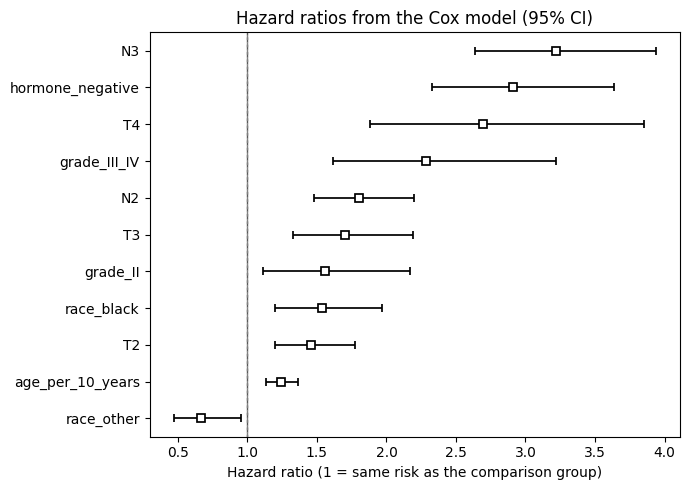

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 5))
cph.plot(hazard_ratios=True, ax=ax)
ax.axvline(1, color="grey", linestyle="--", linewidth=1)
ax.set_title("Hazard ratios from the Cox model (95% CI)")
ax.set_xlabel("Hazard ratio (1 = same risk as the comparison group)")
plt.tight_layout()
plt.show()